In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
print('Libraries imported successfully!')

Libraries imported successfully!


In [ ]:
uploaded = files.upload()
csv_file = next(name for name in uploaded if name.lower().endswith('.csv'))
df = pd.read_csv(csv_file, encoding='unicode_escape')

print('Dataset loaded:', csv_file)
print('Rows and columns:', df.shape)
display(df.head())

Saving Diwali Sales Data.csv to Diwali Sales Data.csv
Dataset loaded: Diwali Sales Data.csv
Rows and columns: (11251, 15)


,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN


In [ ]:
print('Dataset information:')
df.info()
print('\nMissing values per column:')
display(df.isnull().sum().to_frame('Missing values'))
print('\nDuplicate rows:', df.duplicated().sum())
display(df.describe(include='all').T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  object 
 2   Product_ID        11251 non-null  object 
 3   Gender            11251 non-null  object 
 4   Age Group         11251 non-null  object 
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  object 
 8   Zone              11251 non-null  object 
 9   Occupation        11251 non-null  object 
 10  Product_Category  11251 non-null  object 
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), object(8)
memory usage: 1.3+ MB

Missing 

,Missing values
User_ID,0
Cust_name,0
Product_ID,0
Gender,0
Age Group,0
Age,0
Marital_Status,0
State,0
Zone,0
Occupation,0



Duplicate rows: 8


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
User_ID,11251.0,NaN,NaN,NaN,1003004.488134,1716.125402,1000001.0,1001492.0,1003065.0,1004430.0,1006040.0
Cust_name,11251,1250,Vishakha,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_ID,11251,2351,P00265242,53,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,11251,2,F,7842,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age Group,11251,7,26-35,4543,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,11251.0,NaN,NaN,NaN,35.421207,12.754122,12.0,27.0,33.0,43.0,92.0
Marital_Status,11251.0,NaN,NaN,NaN,0.420318,0.493632,0.0,0.0,0.0,1.0,1.0
State,11251,16,Uttar Pradesh,1946,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zone,11251,5,Central,4296,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation,11251,15,IT Sector,1588,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.columns = df.columns.str.strip()
# Remove columns that contain no useful values
df = df.dropna(axis=1, how='all')
df = df.loc[:, ~df.columns.str.lower().str.startswith('unnamed')]
df = df.drop_duplicates()

if 'Amount' in df.columns:
    df['Amount'] = pd.to_numeric(df['Amount'], errors='coerce')
    df = df.dropna(subset=['Amount'])
    df['Amount'] = df['Amount'].astype(float)

print('Cleaned dataset shape:', df.shape)
display(df.head())

Cleaned dataset shape: (11231, 13)


,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0


In [ ]:
print(f"Total transactions/records: {len(df):,}")
if 'User_ID' in df.columns:
    print(f"Unique customers: {df['User_ID'].nunique():,}")
if 'Orders' in df.columns:
    print(f"Total orders (sum of Orders): {df['Orders'].sum():,.0f}")
if 'Amount' in df.columns:
    print(f"Total recorded sales: ₹{df['Amount'].sum():,.2f}")
    print(f"Average purchase amount per record: ₹{df['Amount'].mean():,.2f}")

Total transactions/records: 11,231
Unique customers: 3,752
Total orders (sum of Orders): 27,955
Total recorded sales: ₹106,178,828.43
Average purchase amount per record: ₹9,454.08


,sum,mean,count
Gender,,,
F,74307682.43,9492.550132,7828
M,31871146.00,9365.602703,3403


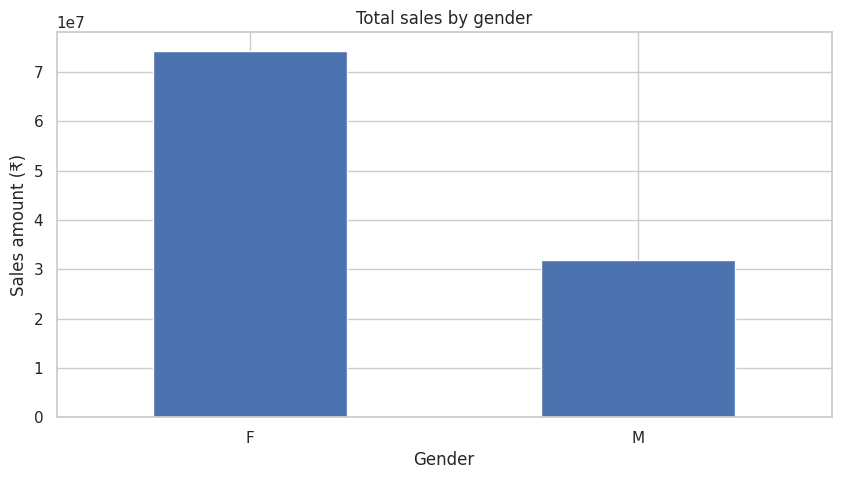

In [ ]:
if {'Gender', 'Amount'}.issubset(df.columns):
    gender_sales = df.groupby('Gender')['Amount'].agg(['sum', 'mean', 'count']).sort_values('sum', ascending=False)
    display(gender_sales)
    gender_sales['sum'].plot(kind='bar', title='Total sales by gender', ylabel='Sales amount (₹)', xlabel='Gender')
    plt.xticks(rotation=0)
    plt.show()
else:
    print('Gender or Amount column not found.')

,Total sales (₹)
Age Group,
26-35,42581768.94
36-45,22135136.49
18-25,17235530.00
46-50,9207844.00
51-55,8237909.00
55+,4080987.00
0-17,2699653.00


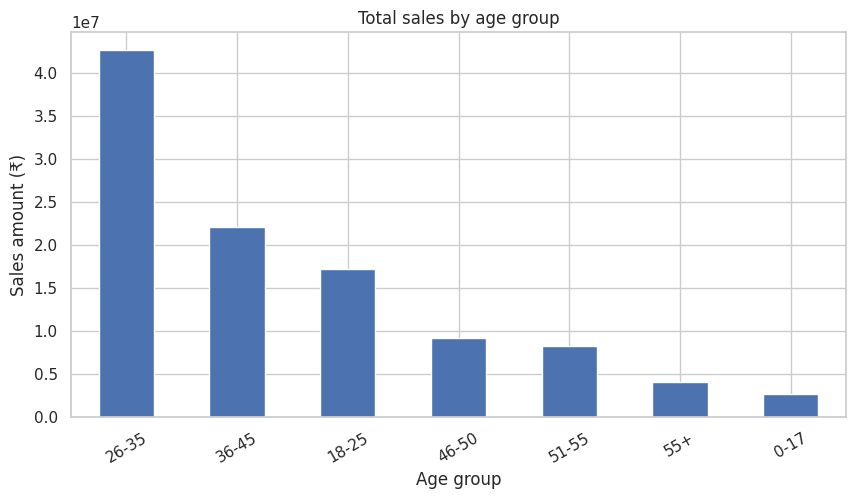

In [ ]:
if {'Age Group', 'Amount'}.issubset(df.columns):
    age_sales = df.groupby('Age Group')['Amount'].sum().sort_values(ascending=False)
    display(age_sales.to_frame('Total sales (₹)'))
    age_sales.plot(kind='bar', title='Total sales by age group', ylabel='Sales amount (₹)', xlabel='Age group')
    plt.xticks(rotation=30)
    plt.show()
else:
    print('Age Group or Amount column not found.')

,Total sales (₹)
State,
Uttar Pradesh,19346055.00
Maharashtra,14404467.00
Karnataka,13523540.00
Delhi,11603819.45
Madhya Pradesh,8101142.00
Andhra Pradesh,8037146.99
Himachal Pradesh,4963368.00
Haryana,4217871.00
Bihar,4014669.00


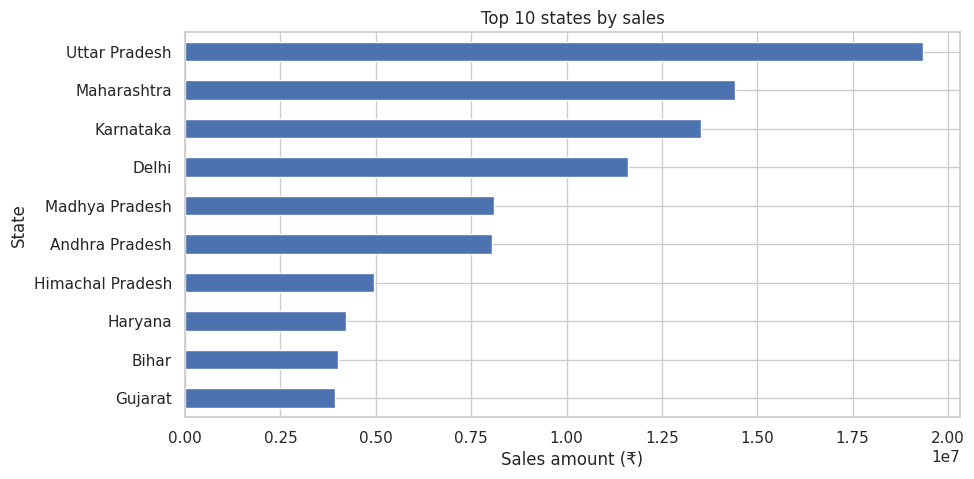

In [ ]:
if {'State', 'Amount'}.issubset(df.columns):
    state_sales = df.groupby('State')['Amount'].sum().sort_values(ascending=False).head(10)
    display(state_sales.to_frame('Total sales (₹)'))
    state_sales.sort_values().plot(kind='barh', title='Top 10 states by sales', xlabel='Sales amount (₹)')
    plt.show()
else:
    print('State or Amount column not found.')

,Orders
Product_Category,
Clothing & Apparel,6627
Food,6110
Electronics & Gadgets,5208
Footwear & Shoes,2646
Household items,1331
Beauty,1086
Games & Toys,940
Furniture,889
Sports Products,870


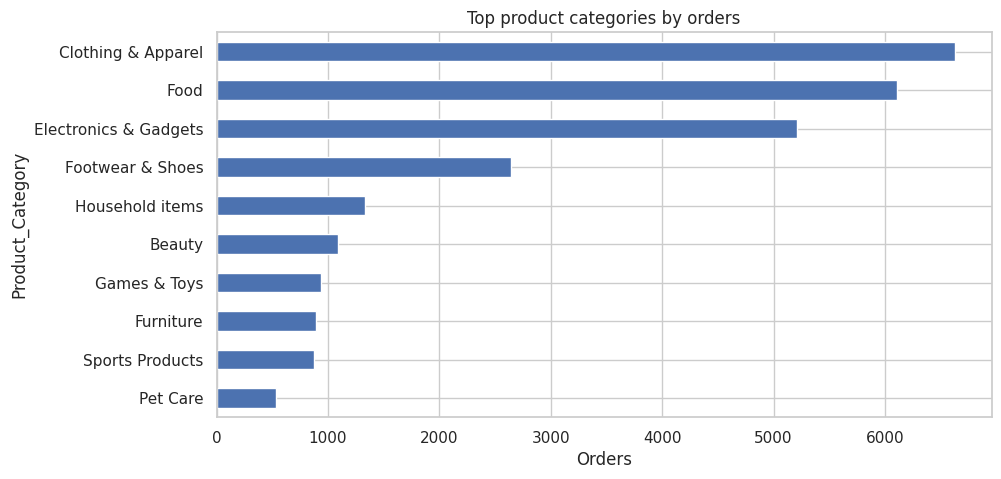

,Sales amount (₹)
Product_Category,
Food,33933883.50
Clothing & Apparel,16484472.00
Electronics & Gadgets,15607657.00
Footwear & Shoes,15575209.45
Furniture,5440051.99
Games & Toys,4331694.00
Sports Products,3635933.00
Beauty,1959484.00
Auto,1935041.99


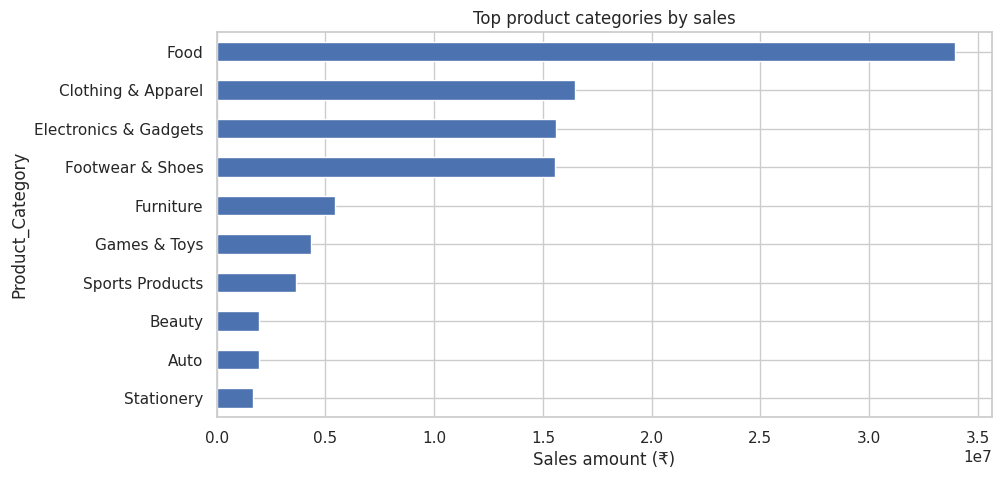

In [ ]:
if 'Product_Category' in df.columns:
    if 'Orders' in df.columns:
        category_orders = df.groupby('Product_Category')['Orders'].sum().sort_values(ascending=False).head(10)
        display(category_orders.to_frame('Orders'))
        category_orders.sort_values().plot(kind='barh', title='Top product categories by orders', xlabel='Orders')
        plt.show()
    if 'Amount' in df.columns:
        category_revenue = df.groupby('Product_Category')['Amount'].sum().sort_values(ascending=False).head(10)
        display(category_revenue.to_frame('Sales amount (₹)'))
        category_revenue.sort_values().plot(kind='barh', title='Top product categories by sales', xlabel='Sales amount (₹)')
        plt.show()
else:
    print('Product_Category column not found.')

,Total sales (₹)
Occupation,
IT Sector,14741862.00
Healthcare,13034587.49
Aviation,12599994.00
Banking,10770610.95
Govt,8517212.00
Hospitality,6337633.00
Media,6295832.99
Automobile,5368596.00
Chemical,5297436.00


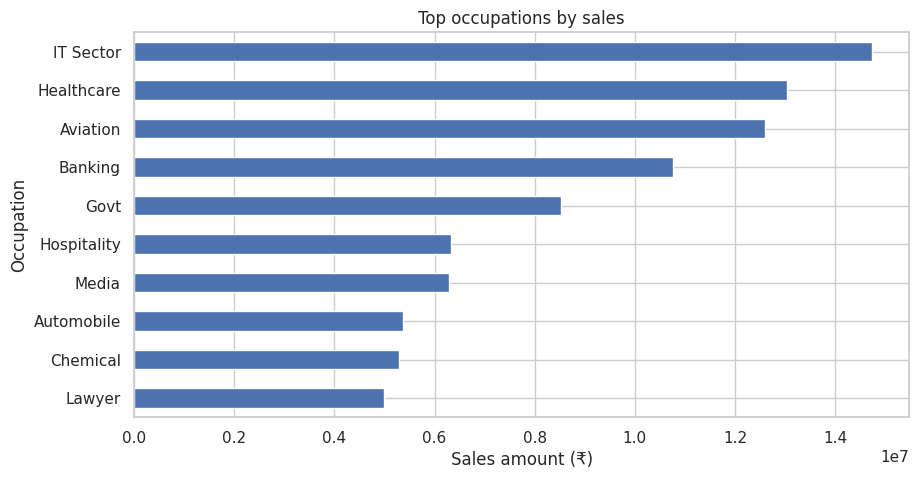

In [ ]:
if {'Occupation', 'Amount'}.issubset(df.columns):
    occupation_sales = df.groupby('Occupation')['Amount'].sum().sort_values(ascending=False).head(10)
    display(occupation_sales.to_frame('Total sales (₹)'))
    occupation_sales.sort_values().plot(kind='barh', title='Top occupations by sales', xlabel='Sales amount (₹)')
    plt.show()
else:
    print('Occupation or Amount column not found.')

,Total sales (₹)
Marital_Status,
0,62098736.44
1,44080091.99


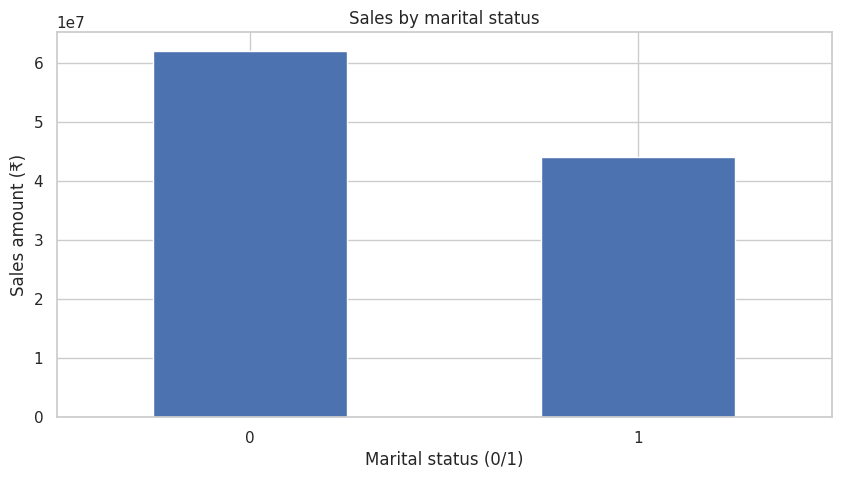

In this dataset, Marital_Status is commonly coded as 0 = unmarried and 1 = married; verify the dataset documentation.


In [ ]:
if {'Marital_Status', 'Amount'}.issubset(df.columns):
    marital_sales = df.groupby('Marital_Status')['Amount'].sum().sort_values(ascending=False)
    display(marital_sales.to_frame('Total sales (₹)'))
    marital_sales.plot(kind='bar', title='Sales by marital status', ylabel='Sales amount (₹)', xlabel='Marital status (0/1)')
    plt.xticks(rotation=0)
    plt.show()
    print('In this dataset, Marital_Status is commonly coded as 0 = unmarried and 1 = married; verify the dataset documentation.')

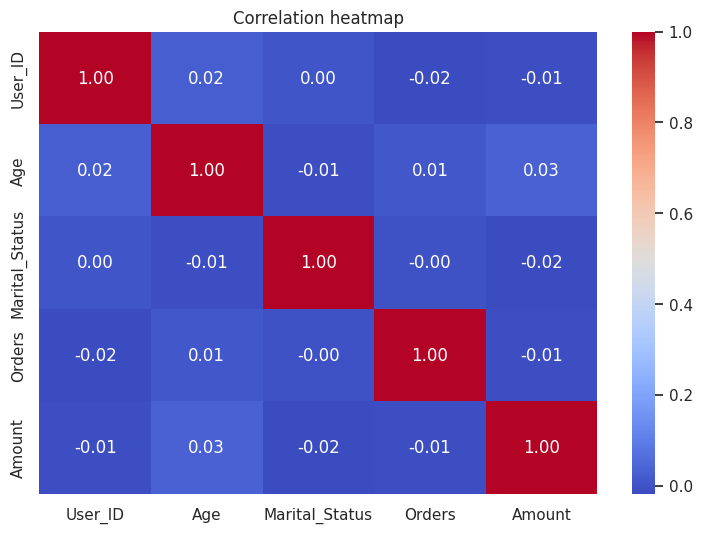

In [ ]:
numeric_df = df.select_dtypes(include=np.number)
if not numeric_df.empty:
    plt.figure(figsize=(9, 6))
    sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation heatmap')
    plt.show()
else:
    print('No numeric columns available for correlation.')

In [ ]:
print('DIWALI SALES - DATA-DRIVEN FINDINGS')
print('=' * 42)
if {'Gender', 'Amount'}.issubset(df.columns):
    g = df.groupby('Gender')['Amount'].sum()
    print('Highest-sales gender:', g.idxmax(), '| Sales: ₹', f'{g.max():,.2f}')
if {'Age Group', 'Amount'}.issubset(df.columns):
    a = df.groupby('Age Group')['Amount'].sum()
    print('Highest-sales age group:', a.idxmax(), '| Sales: ₹', f'{a.max():,.2f}')
if {'State', 'Amount'}.issubset(df.columns):
    s = df.groupby('State')['Amount'].sum()
    print('Top state:', s.idxmax(), '| Sales: ₹', f'{s.max():,.2f}')
if {'Product_Category', 'Amount'}.issubset(df.columns):
    p = df.groupby('Product_Category')['Amount'].sum()
    print('Top revenue category:', p.idxmax(), '| Sales: ₹', f'{p.max():,.2f}')
print('\nUse these results to write recommendations based on the actual data, not assumptions.')

DIWALI SALES - DATA-DRIVEN FINDINGS
Highest-sales gender: F | Sales: ₹ 74,307,682.43
Highest-sales age group: 26-35 | Sales: ₹ 42,581,768.94
Top state: Uttar Pradesh | Sales: ₹ 19,346,055.00
Top revenue category: Food | Sales: ₹ 33,933,883.50

Use these results to write recommendations based on the actual data, not assumptions.
